In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



def design_matrix(X):
    
    ones = np.ones((X.shape[0], 1))
    return np.hstack((ones, X))

def fit_normal_equation(X, y):
   
    A = design_matrix(X)
    return np.linalg.pinv(A.T @ A) @ A.T @ y

def standardize_train_test(X_train, X_test):
    
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    sigma[sigma == 0] = 1.0  
    
    X_train_std = (X_train - mu) / sigma
    X_test_std = (X_test - mu) / sigma
    return X_train_std, X_test_std, mu, sigma

def confusion_matrix_scratch(y_true, y_pred):
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fp, tn, fn

def evaluate_metrics(y_true, y_pred):
   
    tp, fp, tn, fn = confusion_matrix_scratch(y_true, y_pred)
    acc = (tp + tn) / (tp + fp + tn + fn) if (tp + fp + tn + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return acc, prec, rec, f1


In [2]:
df = pd.read_csv("lab7_loans.csv")
features = ["income_k", "utilisation"]
X = df[features].to_numpy(float)
y = df["defaulted"].to_numpy(int)
idx = np.random.default_rng(0).permutation(len(y))
te, tr = idx[:100], idx[100:]
X_train, y_train = X[tr], y[tr]
X_test, y_test = X[te], y[te]
print("train:", X_train.shape, " test:", X_test.shape) # (400, 2) (100, 2)

train: (400, 2)  test: (100, 2)


In [3]:
theta_lin = fit_normal_equation(X_train, y_train.astype(float))
pred = design_matrix(X) @ theta_lin
print("smallest prediction:", pred.min().round(3))
print("largest prediction: ", pred.max().round(3))
print("predictions below 0:", (pred < 0).sum())

smallest prediction: -0.556
largest prediction:  0.848
predictions below 0: 62


In [5]:
df.head()

,income_k,utilisation,defaulted
0,40.5,0.723,0
1,146.6,0.613,0
2,66.1,0.578,0
3,126.7,0.420,0
4,74.9,0.355,0


[]

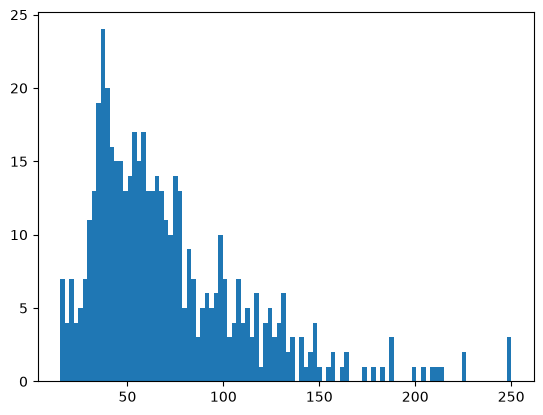

In [23]:
plt.hist(df['income_k'],bins=100)
plt.plot()

(array([ 3.,  2.,  4.,  6.,  8.,  9.,  7., 11., 13., 11., 15., 11.,  9.,
        17., 16., 20., 12., 12., 16., 13., 14., 23., 15., 12., 18., 12.,
        23., 15., 11.,  9., 18., 12., 14.,  8.,  9.,  8., 15.,  3.,  8.,
         6.,  7.,  6.,  5.,  5.,  2.,  2.,  1.,  2.,  0.,  2.]),
 array([0.019  , 0.03804, 0.05708, 0.07612, 0.09516, 0.1142 , 0.13324,
        0.15228, 0.17132, 0.19036, 0.2094 , 0.22844, 0.24748, 0.26652,
        0.28556, 0.3046 , 0.32364, 0.34268, 0.36172, 0.38076, 0.3998 ,
        0.41884, 0.43788, 0.45692, 0.47596, 0.495  , 0.51404, 0.53308,
        0.55212, 0.57116, 0.5902 , 0.60924, 0.62828, 0.64732, 0.66636,
        0.6854 , 0.70444, 0.72348, 0.74252, 0.76156, 0.7806 , 0.79964,
        0.81868, 0.83772, 0.85676, 0.8758 , 0.89484, 0.91388, 0.93292,
        0.95196, 0.971  ]),
 <BarContainer object of 50 artists>)

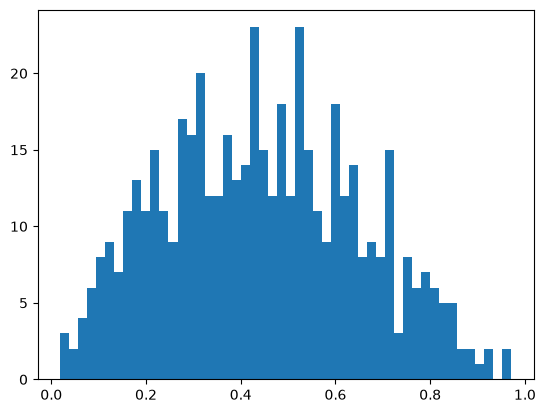

In [27]:
plt.hist(df['utilisation'],bins=50
        )

/tmp/ipykernel_6029/2771673298.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


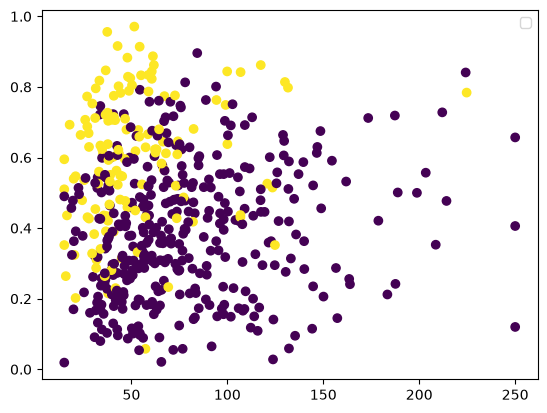

In [21]:
mask=[df['defaulted']==1]

plt.scatter(df['income_k'],df['utilisation'],c=mask)
plt.legend()

In [4]:
def sigmoid(z):
   
    return 1.0 / (1.0 + np.exp(-z))

def log_likelihood(X, y, theta):
    
    A = design_matrix(X)
    h = sigmoid(A @ theta)
    eps = 1e-12  
    h_clipped = np.clip(h, eps, 1.0 - eps)
    l_theta = np.sum(y * np.log(h_clipped) + (1 - y) * np.log(1 - h_clipped))
    return l_theta
X_train_std, X_test_std, mu_train, sigma_train = standardize_train_test(X_train, X_test)

theta_zero = np.zeros(X_train_std.shape[1] + 1)
total_ll_zero = log_likelihood(X_train_std, y_train, theta_zero)
per_example_ll_zero = total_ll_zero / len(y_train)

print(f"Hand calculation per example: log(0.5) = {np.log(0.5):.6f}")
print(f"Log-likelihood at theta = 0 (Total): {total_ll_zero:.4f}")
print(f"Log-likelihood at theta = 0 (Per example): {per_example_ll_zero:.6f}")

Hand calculation per example: log(0.5) = -0.693147
Log-likelihood at theta = 0 (Total): -277.2589
Log-likelihood at theta = 0 (Per example): -0.693147


Fitted theta (intercept, w_income, w_utilisation): [-1.5938 -1.1329  1.3475]


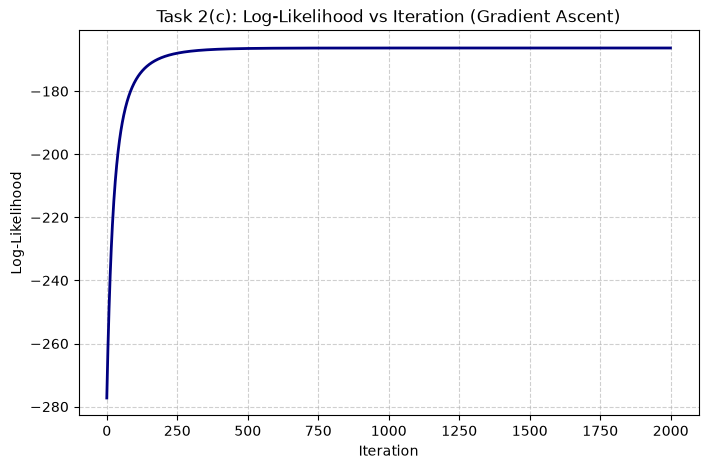

In [14]:
def fit_logistic(X, y, lr=0.1, n_iters=2000):
    A = design_matrix(X)
    m, n = A.shape
    theta = np.zeros(n)
    ll_history = []
    
    for _ in range(n_iters):
        ll_history.append(log_likelihood(X, y, theta))
        predictions = sigmoid(A @ theta)
        gradient = A.T @ (y - predictions)
        theta = theta + (lr / m) * gradient 
        
    return theta, ll_history

theta_fitted, ll_history = fit_logistic(X_train_std, y_train, lr=0.1, n_iters=2000)
print("Fitted theta (intercept, w_income, w_utilisation):", theta_fitted.round(4))
plt.figure(figsize=(8, 5))
plt.plot(ll_history, color='navy', linewidth=2)
plt.title("Task 2(c): Log-Likelihood vs Iteration (Gradient Ascent)")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [16]:
A_test = design_matrix(X_test_std)
p_test = sigmoid(A_test @ theta_fitted)

for th in [0.5, 0.3]:
    y_pred = (p_test >= th).astype(int)
    acc, prec, rec, f1 = evaluate_metrics(y_test, y_pred)
    print(f"Threshold = {th}")
    print(f"Accuracy:  {acc:.4f} (Baseline: 0.7000)")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}\n")

Threshold = 0.5
Accuracy:  0.8200 (Baseline: 0.7000)
Precision: 0.7143
Recall:    0.6667
F1-Score:  0.6897

Threshold = 0.3
Accuracy:  0.8100 (Baseline: 0.7000)
Precision: 0.6279
Recall:    0.9000
F1-Score:  0.7397

